# Práctica 2 — Sesión 1: Métricas desbalanceadas

## Objetivo

Evaluar un problema de clasificación binaria utilizando el dataset Wall-Following Robot Navigation, con el propósito de analizar el efecto del desbalance de clases sobre las métricas de clasificación.

## Metodología

Se reutiliza el dataset procesado en la Práctica 1 y se selecciona una clase minoritaria como clase positiva. Posteriormente, se entrena un modelo Random Forest y se compara su rendimiento con un clasificador trivial que predice siempre la clase negativa.

Se evaluarán accuracy, precision, recall, F1-score y matriz de confusión para determinar las limitaciones de utilizar únicamente accuracy.

Clase minoritaria: Slight-Left-Turn

Distribución de entrenamiento:
clase
0    4102
1     262
Name: count, dtype: int64

Distribución de prueba:
clase
0    1026
1      66
Name: count, dtype: int64


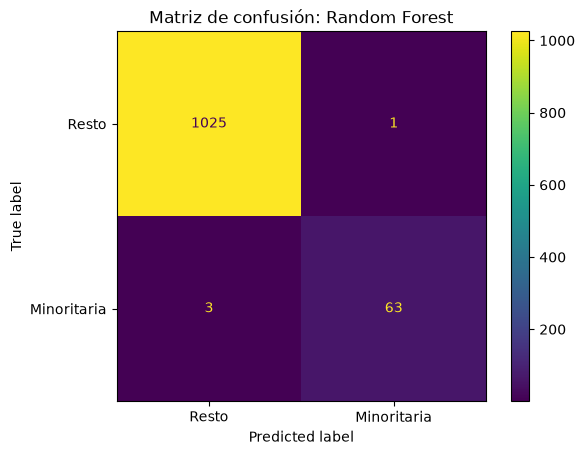

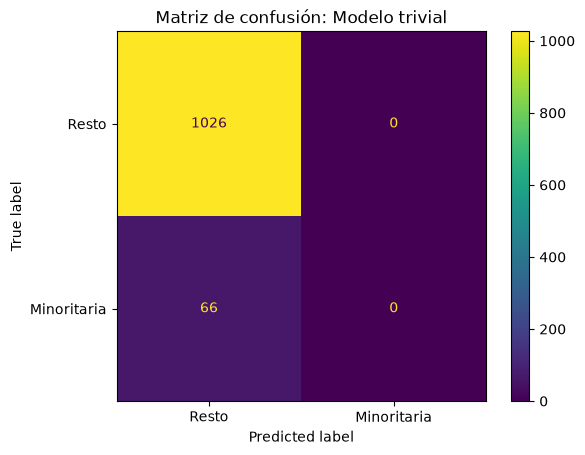


Comparación de métricas:


,Modelo,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.9963,0.9844,0.9545,0.9692
1,Modelo trivial,0.9396,0.0000,0.0000,0.0000


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Cargar los datos preparados en la Práctica 1
df = pd.read_parquet("../../data/processed/dataset.parquet")
# Recuperar la división original
train = df[df["conjunto"] == "train"].copy()
test = df[df["conjunto"] == "test"].copy()

sensores = [f"sensor_{i}" for i in range(1, 25)]

X_train = train[sensores]
X_test = test[sensores]

# Seleccionar la clase minoritaria solo con entrenamiento
clase_minoritaria = train["clase"].value_counts().idxmin()

print("Clase minoritaria:", clase_minoritaria)

# Crear el problema binario
y_train = (train["clase"] == clase_minoritaria).astype(int)
y_test = (test["clase"] == clase_minoritaria).astype(int)

print("\nDistribución de entrenamiento:")
print(y_train.value_counts())

print("\nDistribución de prueba:")
print(y_test.value_counts())

# Entrenar Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

# Modelo trivial: siempre predice 0
modelo_trivial = DummyClassifier(
    strategy="constant",
    constant=0
)

modelo_trivial.fit(X_train, y_train)

# Comparar ambos modelos
resultados = []

for nombre, modelo in [
    ("Random Forest", modelo_rf),
    ("Modelo trivial", modelo_trivial)
]:
    predicciones = modelo.predict(X_test)

    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, predicciones),
        "Precision": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicciones, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predicciones, zero_division=0
        )
    })

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicciones,
        labels=[0, 1],
        display_labels=["Resto", "Minoritaria"]
    )

    plt.title(f"Matriz de confusión: {nombre}")
    plt.show()

tabla = pd.DataFrame(resultados)

print("\nComparación de métricas:")
display(tabla.round(4))

### Conclusión de la sesión P2-1

El modelo trivial obtuvo un accuracy del 93,96 %, pero su precision, recall y F1-score fueron del 0 %, lo que demuestra que accuracy puede resultar engañoso cuando existe desbalance de clases.

Random Forest alcanzó un accuracy del 99,63 %, precision del 98,44 %, recall del 95,45 % y F1-score del 96,92 %, demostrando una mayor capacidad para identificar la clase minoritaria.

Por lo tanto, las métricas precision, recall y F1-score permiten realizar una evaluación más completa y confiable que accuracy por sí sola.

### Conclusión de la sesión P2-1

El modelo trivial obtuvo un accuracy del 93,96 %, pero precision, recall y F1-score iguales a cero, demostrando que accuracy puede ser engañoso ante el desbalance de clases.

Random Forest alcanzó un accuracy del 99,63 %, precision del 98,44 %, recall del 95,45 % y F1-score del 96,92 %, identificando correctamente la mayoría de los casos positivos.

Por lo tanto, es necesario evaluar conjuntamente accuracy, precision, recall, F1-score y la matriz de confusión para comprender el rendimiento del modelo.